# RegExplain: E1 - CNN training and evaluation

This notebook trains the two same small CNN (different seeds ) models from scratch for GATA1 on simulated Tier 0 data and for CTCF on the supplied Tier 1 K562 data.

- **Tier 0:** seeds 565 and 566 generate independent datasets and independently initialize the two CNNs. Each dataset follows the PDF Section 3 recipe: 10,000 sequences of 101 bp; background A/C/G/T probabilities of 0.3/0.2/0.2/0.3; 1-3 non-overlapping motif copies planted in half the sequences. The planted positions are recorded. Each shuffled dataset is split into 7,000 training, 1,500 validation, and 1,500 test sequences.
- **Tier 1:** both seeds use the same supplied CTCF/K562 sequences, dinucleotide-shuffled negatives, and fixed chromosome splits. The seeds change initialization and batch order, not the dataset. One Tier 1 model is enough; the second is retained for a later within-CTCF transferability test.
- **Training:** identical architecture, Adam, learning rate 0.001, batch size 128, and 10 epochs for all four models. The lowest validation loss selects the checkpoint. Test labels are not used for training or checkpoint selection.
- **Evaluation:** test AUROC, average precision (AP), calibration curves, and activation-based logos for all 64 first-layer filters. Full-motif similarity and partial-motif similarity are reported separately. Correlation thresholds are descriptive choices, not proof that a filter is a biological binding site.



## 1. Setup

Use the unchanged course `requirements.txt` in an isolated Jupyter environment. The next cell installs all ten pinned course packages, checks for packages left over in memory from a different installation, and records versions. If it requests a restart, restart the kernel after installation and run from the first cell again. Installing packages inside a running Colab session can conflict with Colab's own dependencies; an isolated local Jupyter environment avoids that specific conflict.

The saved verification run uses Python 3.12 and CPU. The package versions and seeds are fixed; hardware and numerical-library differences can still produce small numerical differences. Run the notebook from top to bottom. Each model's training results, calibration figure, and filter-logo figure have separate cells.

- **For local Jupyter on macOS/Linux**, put this notebook and the supplied `requirements.txt` in one folder. In a terminal opened in that folder, run:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt notebook ipykernel
python -m ipykernel install --user --name regexplain --display-name "Python (RegExplain)"
python -m notebook
```
- **Or Use VScode**,run with python 
- **For Colab**, Restart first and the run all


Course sources: [project PDF](https://github.com/yueliyl/RegExplain/blob/4e496fea9460db51f2d0ab355681f53cab5a9cb4/COMP565_Fall2026_Course_Project_RegExplain.pdf) and [README](https://github.com/yueliyl/RegExplain/blob/4e496fea9460db51f2d0ab355681f53cab5a9cb4/README.md).


In [1]:
# Install the versions pinned in the course requirements.txt.
from urllib.request import urlretrieve
urlretrieve("https://raw.githubusercontent.com/yueliyl/RegExplain/4e496fea9460db51f2d0ab355681f53cab5a9cb4/requirements.txt", "requirements.txt")
%pip install -q -r requirements.txt

# A package that was already loaded keeps its old version until the session restarts.
import sys
from importlib.metadata import version
for name in ("torch", "numpy", "pandas", "matplotlib", "sklearn", "scipy", "logomaker"):
    if name in sys.modules:
        loaded = sys.modules[name].__version__.split("+")[0]
        installed = version("scikit-learn" if name == "sklearn" else name).split("+")[0]
        assert loaded == installed, (
            f"{name} {installed} is installed, but {loaded} is still loaded. "
            "Restart the session (Colab: Runtime > Restart session), then run all cells again.")

import json
import zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import logomaker
from pathlib import Path
from copy import deepcopy
from urllib.request import urlretrieve
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.calibration import CalibrationDisplay

required = dict(line.split("==") for line in Path("requirements.txt").read_text().splitlines() if "==" in line)
packages = list(required)
for name, expected in required.items():
    assert version(name).split("+")[0] == expected, f"Check the installation of {name}."
print("Versions:", {name: version(name) for name in packages})
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("Device:", device)

Note: you may need to restart the kernel to use updated packages.
Versions: {'torch': '2.14.1', 'captum': '0.9.0', 'dice-ml': '0.12', 'memelite': '0.5.0', 'numpy': '2.4.4', 'pandas': '3.0.2', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.9', 'logomaker': '0.8.7', 'scipy': '1.17.1'}
Device: cpu


## 2. Simulate Tier 0 data
The recipe is the one in Section 3 of the project PDF: 10,000 sequences of 101 bp are drawn from a background with P(A, C, G, T) = 0.3, 0.2, 0.2, 0.3. Half of them receive 1 to 3 non-overlapping GATA1 motifs (label 1); the other half are left as background (label 0).

In `X`, A/C/G/T are encoded as 0/1/2/3. `y` contains the labels, and `mask` marks the planted motif positions. The motif is checked before any training: it must carry at least 8 bits of information, and the supplied matrix should give about 8.5.

In [2]:
# Use the specified background and motif, with columns in A, C, G, T order.
background = np.array([0.3, 0.2, 0.2, 0.3])
motif = np.array([
    [.10, .05, .05, .80],
    [.03, .03, .91, .03],
    [.91, .03, .03, .03],
    [.03, .03, .03, .91],
    [.91, .03, .03, .03],
    [.88, .04, .04, .04],
    [.05, .05, .85, .05]
])

# Check the motif before training: rows sum to 1, and it carries at least 8 bits (about 8.5).
assert np.allclose(motif.sum(axis=1), 1)
information = np.sum(motif * np.log2(motif / background))
print(f"Information content: {information:.2f} bits")
assert information >= 8

# Plant 1–3 non-overlapping motif copies in half the sequences, then shuffle rows.
def simulate(n, seed):
    rng = np.random.default_rng(seed)
    X = rng.choice(4, size=(n, 101), p=background).astype(np.int8)
    y = np.zeros(n, dtype=np.float32)
    mask = np.zeros((n, 101), dtype=bool)
    for i in range(n // 2):
        starts = []
        n_copies = rng.integers(1, 4)
        while len(starts) < n_copies:
            s = rng.integers(0, 95)
            if all(abs(s - t) >= 7 for t in starts):
                starts.append(s)
        for s in starts:
            for j in range(7):
                X[i, s + j] = rng.choice(4, p=motif[j])
            mask[i, s:s + 7] = True
        y[i] = 1
    order = rng.permutation(n)
    return X[order], y[order], mask[order]

Information content: 8.54 bits


## 3. Batches and CNN

DNA is one-hot encoded in A/C/G/T order. The shape changes are:

`(batch, 4, 101) -> Conv1d(4, 64, 15, padding=7) -> ReLU -> MaxPool1d(2) -> Conv1d(64, 64, 7, padding=3) -> ReLU -> GlobalMaxPool -> Linear(64, 32) -> ReLU -> Linear(32, 1)`.

The spatial lengths are 101, 50, 50, and 1 after the respective convolution/pooling steps. Because the second convolution outputs exactly 50 positions, `MaxPool1d(50)` implements global max pooling here. This follows the small CNN described in PDF Section 2. Padding preserves the length at each convolution.

The network outputs **logits**. `BCEWithLogitsLoss` includes the sigmoid internally during training; sigmoid is applied explicitly when converting the final predictions to probabilities. Do not add another sigmoid before that loss.

In [3]:
# One-hot encode DNA and set a reproducible batch order.
def make_loader(X, y, shuffle=False, seed=565):
    X = torch.tensor(np.eye(4)[X].transpose(0, 2, 1), dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
    return DataLoader(TensorDataset(X, y), batch_size=128, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed))

# Build the same padded CNN with a fresh initialization.
def make_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Conv1d(4, 64, 15, padding=7), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(64, 64, 7, padding=3), nn.ReLU(), nn.MaxPool1d(50),
        nn.Flatten(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1)
    ).to(device)

## 4. Training
Binary cross-entropy on the logits, Adam with learning rate 0.001, batch size 128, 10 epochs. The validation loss is computed after every epoch, and the weights with the lowest validation loss are restored at the end.

In [4]:
# Train for 10 epochs and restore the weights with the lowest validation loss.
def train_model(model, train_loader, val_loader):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    best_loss, history = float("inf"), []
    for epoch in range(10):
        model.train()
        for X, y in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(X.to(device)), y.to(device))
            loss.backward()
            optimizer.step()
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X, y in val_loader:
                val_loss += loss_fn(model(X.to(device)), y.to(device)).item() * len(y)
        val_loss /= len(val_loader.dataset)
        history.append(val_loss)
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = deepcopy(model.state_dict())
        print(f"Epoch {epoch + 1}: val_loss={val_loss:.4f}")
    model.load_state_dict(best_state)
    return model, history

## 5. First-layer filter logos

For each filter, take the strongest complete 15-bp window from each validation sequence, then keep at most 100 sequences with the highest positive activation. Zero-padded edge windows are excluded. Pool the base counts of these windows to make the logo. This shows sequence patterns associated with strong filter activation; it is not a direct plot of convolution weights and does not prove causality. All 64 filters are shown.

Compare each window-frequency matrix with the reference motif using Pearson correlation:

- **Full motif:** require the entire reference motif to fit in the 15-bp window. GATA1 has nine possible full placements; the 15-bp CTCF reference has one per strand.
- **Partial or full motif:** also allow shifted alignments with at least 7 overlapping positions. The title reports the best correlation and overlap length. Bold titles pass the descriptive 0.90 threshold for that alignment.

Thresholds are applied to **unrounded** correlations. Rounded values are only for display. A partial CTCF match does not count as full-motif recovery. Searching more offsets and both strands gives more opportunities for high correlation, so partial and full counts, and counts across TFs, are not equivalent measures. No significance test or multiple-comparison correction is claimed.

In [5]:
# Pearson correlation between a filter's 15-bp matrix and a known motif, at every alignment
# in which the two overlap by at least 7 positions. Gives (r, overlap length) per alignment.
def alignments(probs, known):
    pairs = []
    for shift in range(7 - len(known), 9):
        lo, hi = max(shift, 0), min(shift + len(known), 15)
        r = np.corrcoef(probs[lo:hi].ravel(), known[lo - shift:hi - shift].ravel())[0, 1]
        pairs.append((np.nan_to_num(r, nan=-1.0), hi - lo))
    return pairs

# Draw the known motif on the same scale and with the same colors as the filter logos.
def plot_motif(known, titles, background, path):
    width = sum(0.4 * len(m) + 1.2 for m in known)
    fig, axes = plt.subplots(1, len(known), figsize=(width, 2.4), squeeze=False, layout="constrained")
    for ax, m, title in zip(axes[0], known, titles):
        logo = logomaker.transform_matrix(pd.DataFrame(m, columns=list("ACGT")), from_type="probability",
                                          to_type="information", background=background)
        logomaker.Logo(logo, ax=ax, color_scheme="classic", font_name="DejaVu Sans")
        ax.set(title=title, xlabel="Motif position", ylabel="Information (bits)", ylim=(0, 2.4))
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Build sequence logos from the validation windows that activate each filter,
# and summarize full and partial similarity to the reference motif.
def plot_filters(model, loader, X, path, known, background, label):
    model.eval()
    with torch.no_grad():
        a = torch.cat([model[:2](x.to(device)).cpu() for x, _ in loader]).numpy()
    a = a[:, :, 7:-7]
    fig, axes = plt.subplots(8, 8, figsize=(20, 16), layout="constrained")
    best_r, whole_r = np.full(64, np.nan), np.full(64, np.nan)
    overlaps = np.zeros(64, dtype=int)
    for k, ax in enumerate(axes.flat):
        peak = a[:, k].max(axis=1)
        top = np.argsort(peak)[-100:]
        top = top[peak[top] > 0]
        if len(top) == 0:
            ax.set_title(f"Filter {k + 1}: inactive", fontsize=8)
            ax.axis("off")
            continue
        start = a[top, k].argmax(axis=1)
        windows = np.array([X[i, s:s + 15] for i, s in zip(top, start)])
        counts = pd.DataFrame(np.eye(4)[windows].sum(axis=0), columns=list("ACGT"))
        probs = (counts.values + 1) / (counts.values + 1).sum(axis=1, keepdims=True)
        pairs = [pair for m in known for pair in alignments(probs, m)]
        r, overlap = max(pairs)
        best_r[k] = r
        overlaps[k] = overlap
        whole_r[k] = max(c for c, n in pairs if n == len(known[0]))
        logo = logomaker.transform_matrix(counts, from_type="counts", to_type="information",
                                          background=background, pseudocount=1)
        logomaker.Logo(logo, ax=ax, color_scheme="classic", font_name="DejaVu Sans")
        ax.set_title(f"Filter {k + 1}: r = {best_r[k]:.3f}\n{overlap}/{len(known[0])} motif positions", fontsize=9,
                     fontweight="bold" if best_r[k] >= 0.9 else "normal")
        ax.set(xticks=[0, 7, 14], ylim=(0, 2.4))
    fig.suptitle(f"{label}: first-layer activation logos")
    fig.supxlabel("Position within the 15-bp window")
    fig.supylabel("Information (bits)")
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    pd.DataFrame({"filter": np.arange(1, 65), "best_partial_or_full_r": best_r,
                  "overlap_bp": overlaps, "best_full_motif_r": whole_r}).to_csv(
                      path.with_name("filter_similarity.csv"), index=False)
    similar, whole = int((best_r >= 0.9).sum()), int((whole_r >= 0.9).sum())
    print(f"Descriptive similarity r >= 0.90: {similar}/64 partial or full; "
          f"{whole}/64 across all {len(known[0])} motif positions.")
    return similar, whole

## 6. Shared training, evaluation, and saving

Each model trains only on its training split. The lowest validation loss selects the checkpoint, which is then evaluated on the test split. Calibration is reported on that held-out split; it is not fitted to the test labels. A reload check compares saved and restored predictions without changing the weights.

Each run has its own `e1_results/tier<tier>_seed<seed>/` folder. Validation losses, test predictions, raw filter correlations, calibration-bin counts, metrics, and model weights are saved for inspection. A loss-curve figure is optional; E1 specifically requests the held-out metrics, calibration curve, and first-layer logos.

In [6]:
root = Path("e1_results")
root.mkdir(exist_ok=True)
metrics = {}

def run_model(tier, number, seed, train, val, test, known, background):
    label = f"Tier {tier}, Model {number} (seed {seed})"
    print(label)
    out = root / f"tier{tier}_seed{seed}"
    out.mkdir(exist_ok=True)
    train_loader = make_loader(*train, shuffle=True, seed=seed)
    val_loader = make_loader(*val)
    test_loader = make_loader(*test)
    model, history = train_model(make_model(seed), train_loader, val_loader)

    # Evaluate the selected model on the untouched test split.
    model.eval()
    with torch.no_grad():
        p = torch.cat([model(x.to(device)).sigmoid().cpu() for x, _ in test_loader]).numpy().ravel()
    auc = roc_auc_score(test[1], p)
    ap = average_precision_score(test[1], p)
    print(f"Test AUROC: {auc:.4f} | Test AUPRC (AP): {ap:.4f}")

    metrics[tier, seed] = {"tier": tier, "model": number, "seed": seed, "AUROC": auc, "AP": ap,
                           "best_epoch": int(np.argmin(history) + 1)}
    pd.DataFrame({"epoch": range(1, 11), "val_loss": history}).to_csv(out / "training.csv", index=False)
    pd.DataFrame({"y_test": test[1], "p_test": p}).to_csv(out / "test_predictions.csv", index=False)

    # Save the model, then reload it and verify its predictions on one test batch.
    torch.save({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
                "tier": tier, "seed": seed, "padding": True, "architecture": str(model),
                "base_order": "ACGT", "output": "logits"}, out / "model.pt")
    check = make_model(seed)
    check.load_state_dict(torch.load(out / "model.pt", map_location=device, weights_only=True)["state_dict"])
    check.eval()
    with torch.no_grad():
        restored = check(next(iter(test_loader))[0].to(device)).sigmoid().cpu().numpy().ravel()
    np.testing.assert_allclose(restored, p[:len(restored)], rtol=1e-5, atol=1e-6)
    print("Saved; reload check passed.")
    return model, p

# Display one calibration figure and save its bin counts.
def show_calibration(tier, number, seed, y, p):
    out = root / f"tier{tier}_seed{seed}"
    CalibrationDisplay.from_predictions(y, p, n_bins=10, name=f"Model {number}")
    plt.title(f"Tier {tier}, Model {number} (seed {seed}): test calibration")
    plt.savefig(out / "calibration.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    bins = pd.DataFrame({"bin": np.searchsorted(np.linspace(0, 1, 11)[1:-1], p), "p": p, "y": y})
    bins.groupby("bin").agg(n=("y", "size"), predicted=("p", "mean"), observed=("y", "mean")).to_csv(out / "calibration_bins.csv")

# Display one filter figure and update this model's summary.
def show_filters(tier, number, seed, model, val, known, background):
    out = root / f"tier{tier}_seed{seed}"
    similar, whole = plot_filters(model, make_loader(*val), val[0], out / "filters.png",
                                 known, background, f"Tier {tier}, Model {number} (seed {seed})")
    metrics[tier, seed].update(filters_partial_or_full=similar, filters_full_motif=whole)

## 7. Tier 0
Each seed simulates its own dataset and splits it into 7,000 / 1,500 / 1,500 sequences for training, validation and test. The PWM-scan ceiling is checked before training: every 7-bp window is scored with the log-odds matrix, and the best score per sequence is used as the prediction. The data, labels, test mask and test predictions are saved next to the model for future tasks.

The known motif is drawn first, on the same scale as the filter logos.

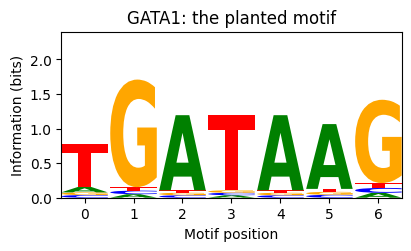

In [7]:
log_odds = np.log2(motif / background)

def run_tier0(number, seed):
    X, y, mask = simulate(10000, seed)

    # PWM-scan ceiling: score all 95 windows and keep the best score per sequence.
    scores = np.zeros((len(X), 95))
    for j in range(7):
        scores += log_odds[j, X[:, j:j + 95]]
    pwm_auc = roc_auc_score(y, scores.max(axis=1))
    print(f"PWM-scan AUROC: {pwm_auc:.4f}")
    assert pwm_auc > 0.9, "Check the simulation before training."

    # The motif was only planted on the forward strand, so only that orientation is compared.
    model, p = run_model(0, number, seed, (X[:7000], y[:7000]), (X[7000:8500], y[7000:8500]),
                         (X[8500:], y[8500:]), [motif], background)
    metrics[0, seed]["PWM_AUROC"] = pwm_auc
    np.savez_compressed(root / f"tier0_seed{seed}" / "data.npz", X_train=X[:7000], y_train=y[:7000],
                        X_val=X[7000:8500], y_val=y[7000:8500],
                        X_test=X[8500:], y_test=y[8500:], mask_test=mask[8500:],
                        p_test=p, motif=motif, background=background)
    return model, X, y, mask, p

plot_motif([motif], ["GATA1: the planted motif"], background, root / "tier0_known_motif.png")

### Tier 0, Model 1 (seed 565)

In [8]:
# Keep familiar variable names for later attribution work.
model, X, y, mask, p = run_tier0(1, 565)
X_test, y_test, mask_test = X[8500:], y[8500:], mask[8500:]

PWM-scan AUROC: 0.9520
Tier 0, Model 1 (seed 565)
Epoch 1: val_loss=0.6913
Epoch 2: val_loss=0.6674
Epoch 3: val_loss=0.3770
Epoch 4: val_loss=0.2692
Epoch 5: val_loss=0.2661
Epoch 6: val_loss=0.2706
Epoch 7: val_loss=0.2667
Epoch 8: val_loss=0.2673
Epoch 9: val_loss=0.2709
Epoch 10: val_loss=0.2748
Test AUROC: 0.9574 | Test AUPRC (AP): 0.9624
Saved; reload check passed.


#### Calibration: Tier 0, Model 1

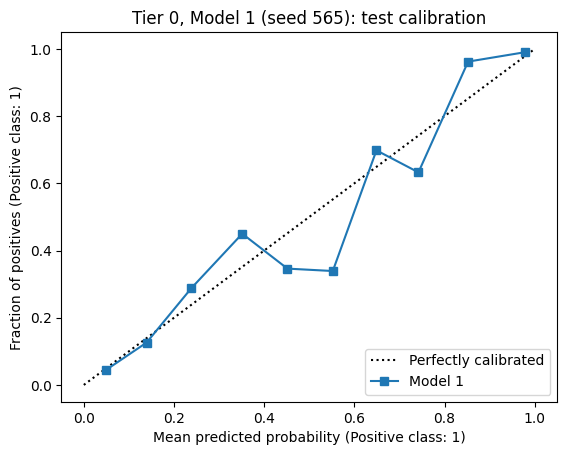

In [9]:
# Plot calibration using final test predictions.
show_calibration(0, 1, 565, y[8500:], p)

#### First-layer filters: Tier 0, Model 1

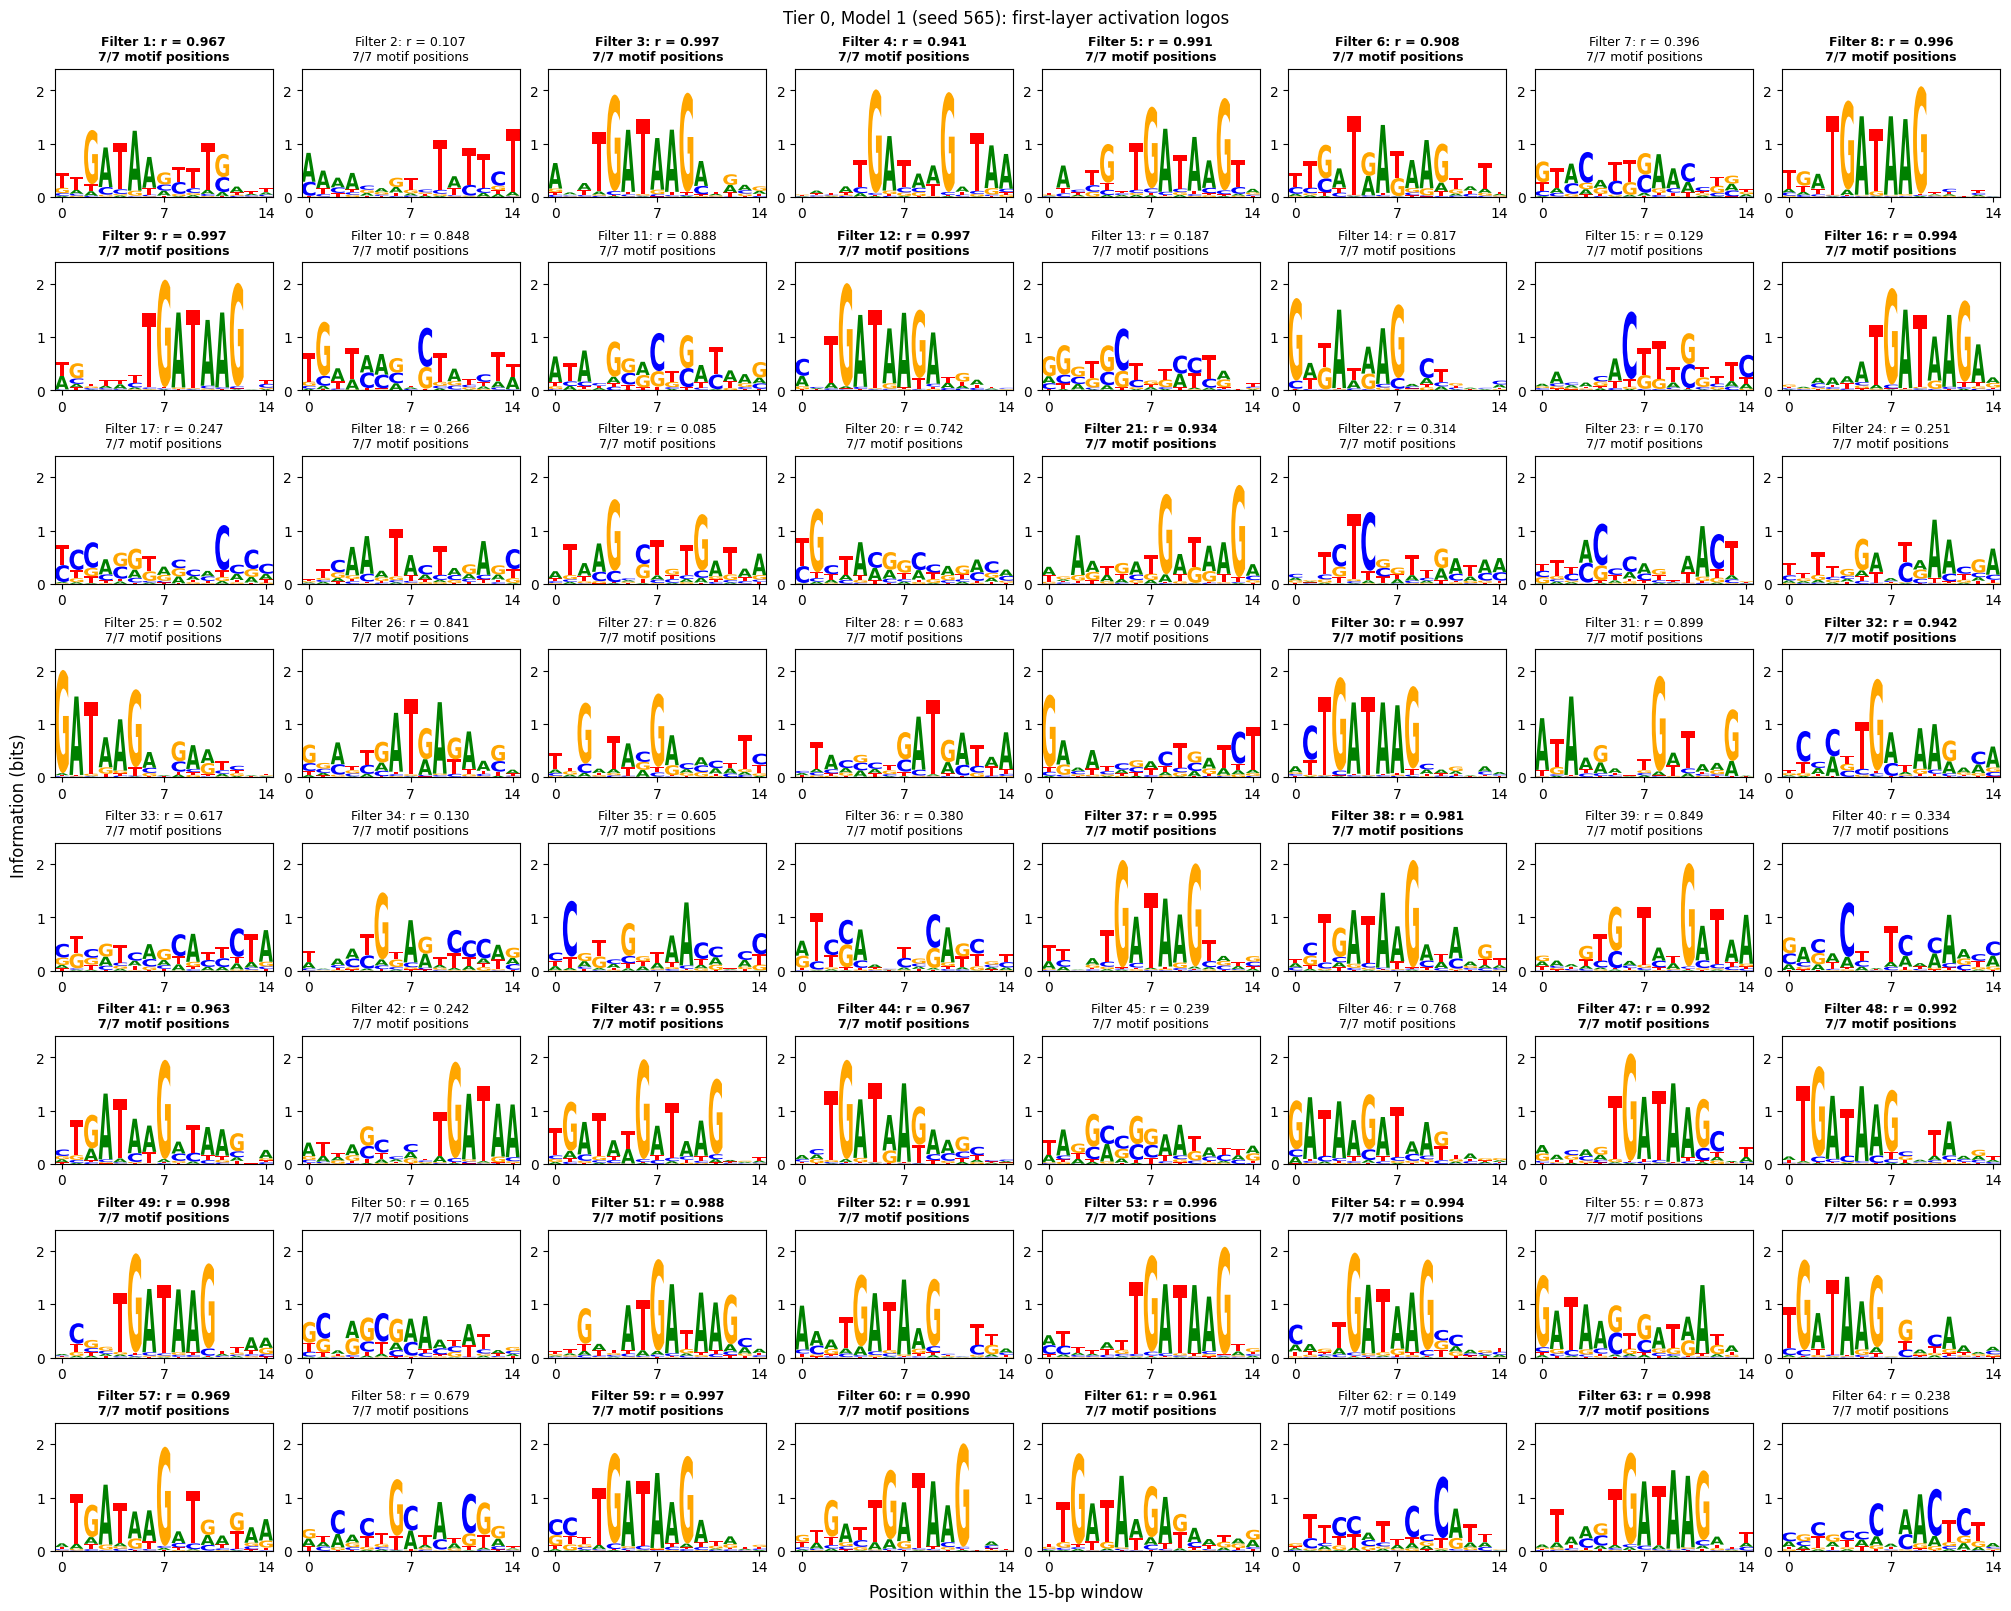

Descriptive similarity r >= 0.90: 30/64 partial or full; 30/64 across all 7 motif positions.


In [10]:
# Use validation windows only for filter interpretation.
show_filters(0, 1, 565, model, (X[7000:8500], y[7000:8500]), [motif], background)

### Tier 0, Model 2 (seed 566)

In [11]:
model2, X2, y2, mask2, p2 = run_tier0(2, 566)

PWM-scan AUROC: 0.9463
Tier 0, Model 2 (seed 566)
Epoch 1: val_loss=0.6417
Epoch 2: val_loss=0.3202
Epoch 3: val_loss=0.2870
Epoch 4: val_loss=0.2846
Epoch 5: val_loss=0.2861
Epoch 6: val_loss=0.2871
Epoch 7: val_loss=0.3049
Epoch 8: val_loss=0.3010
Epoch 9: val_loss=0.2798
Epoch 10: val_loss=0.2790
Test AUROC: 0.9454 | Test AUPRC (AP): 0.9551
Saved; reload check passed.


#### Calibration: Tier 0, Model 2

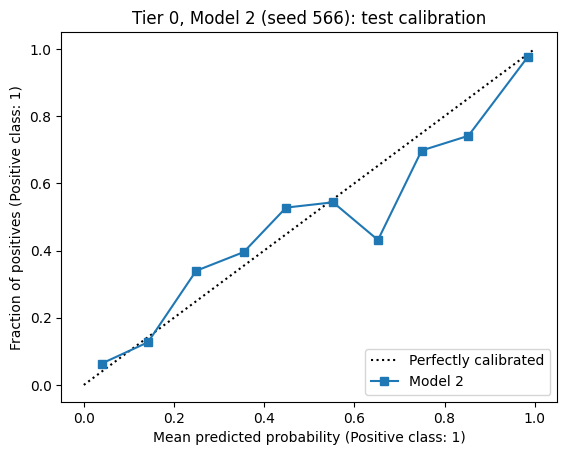

In [12]:
# Plot calibration using final test predictions.
show_calibration(0, 2, 566, y2[8500:], p2)

#### First-layer filters: Tier 0, Model 2

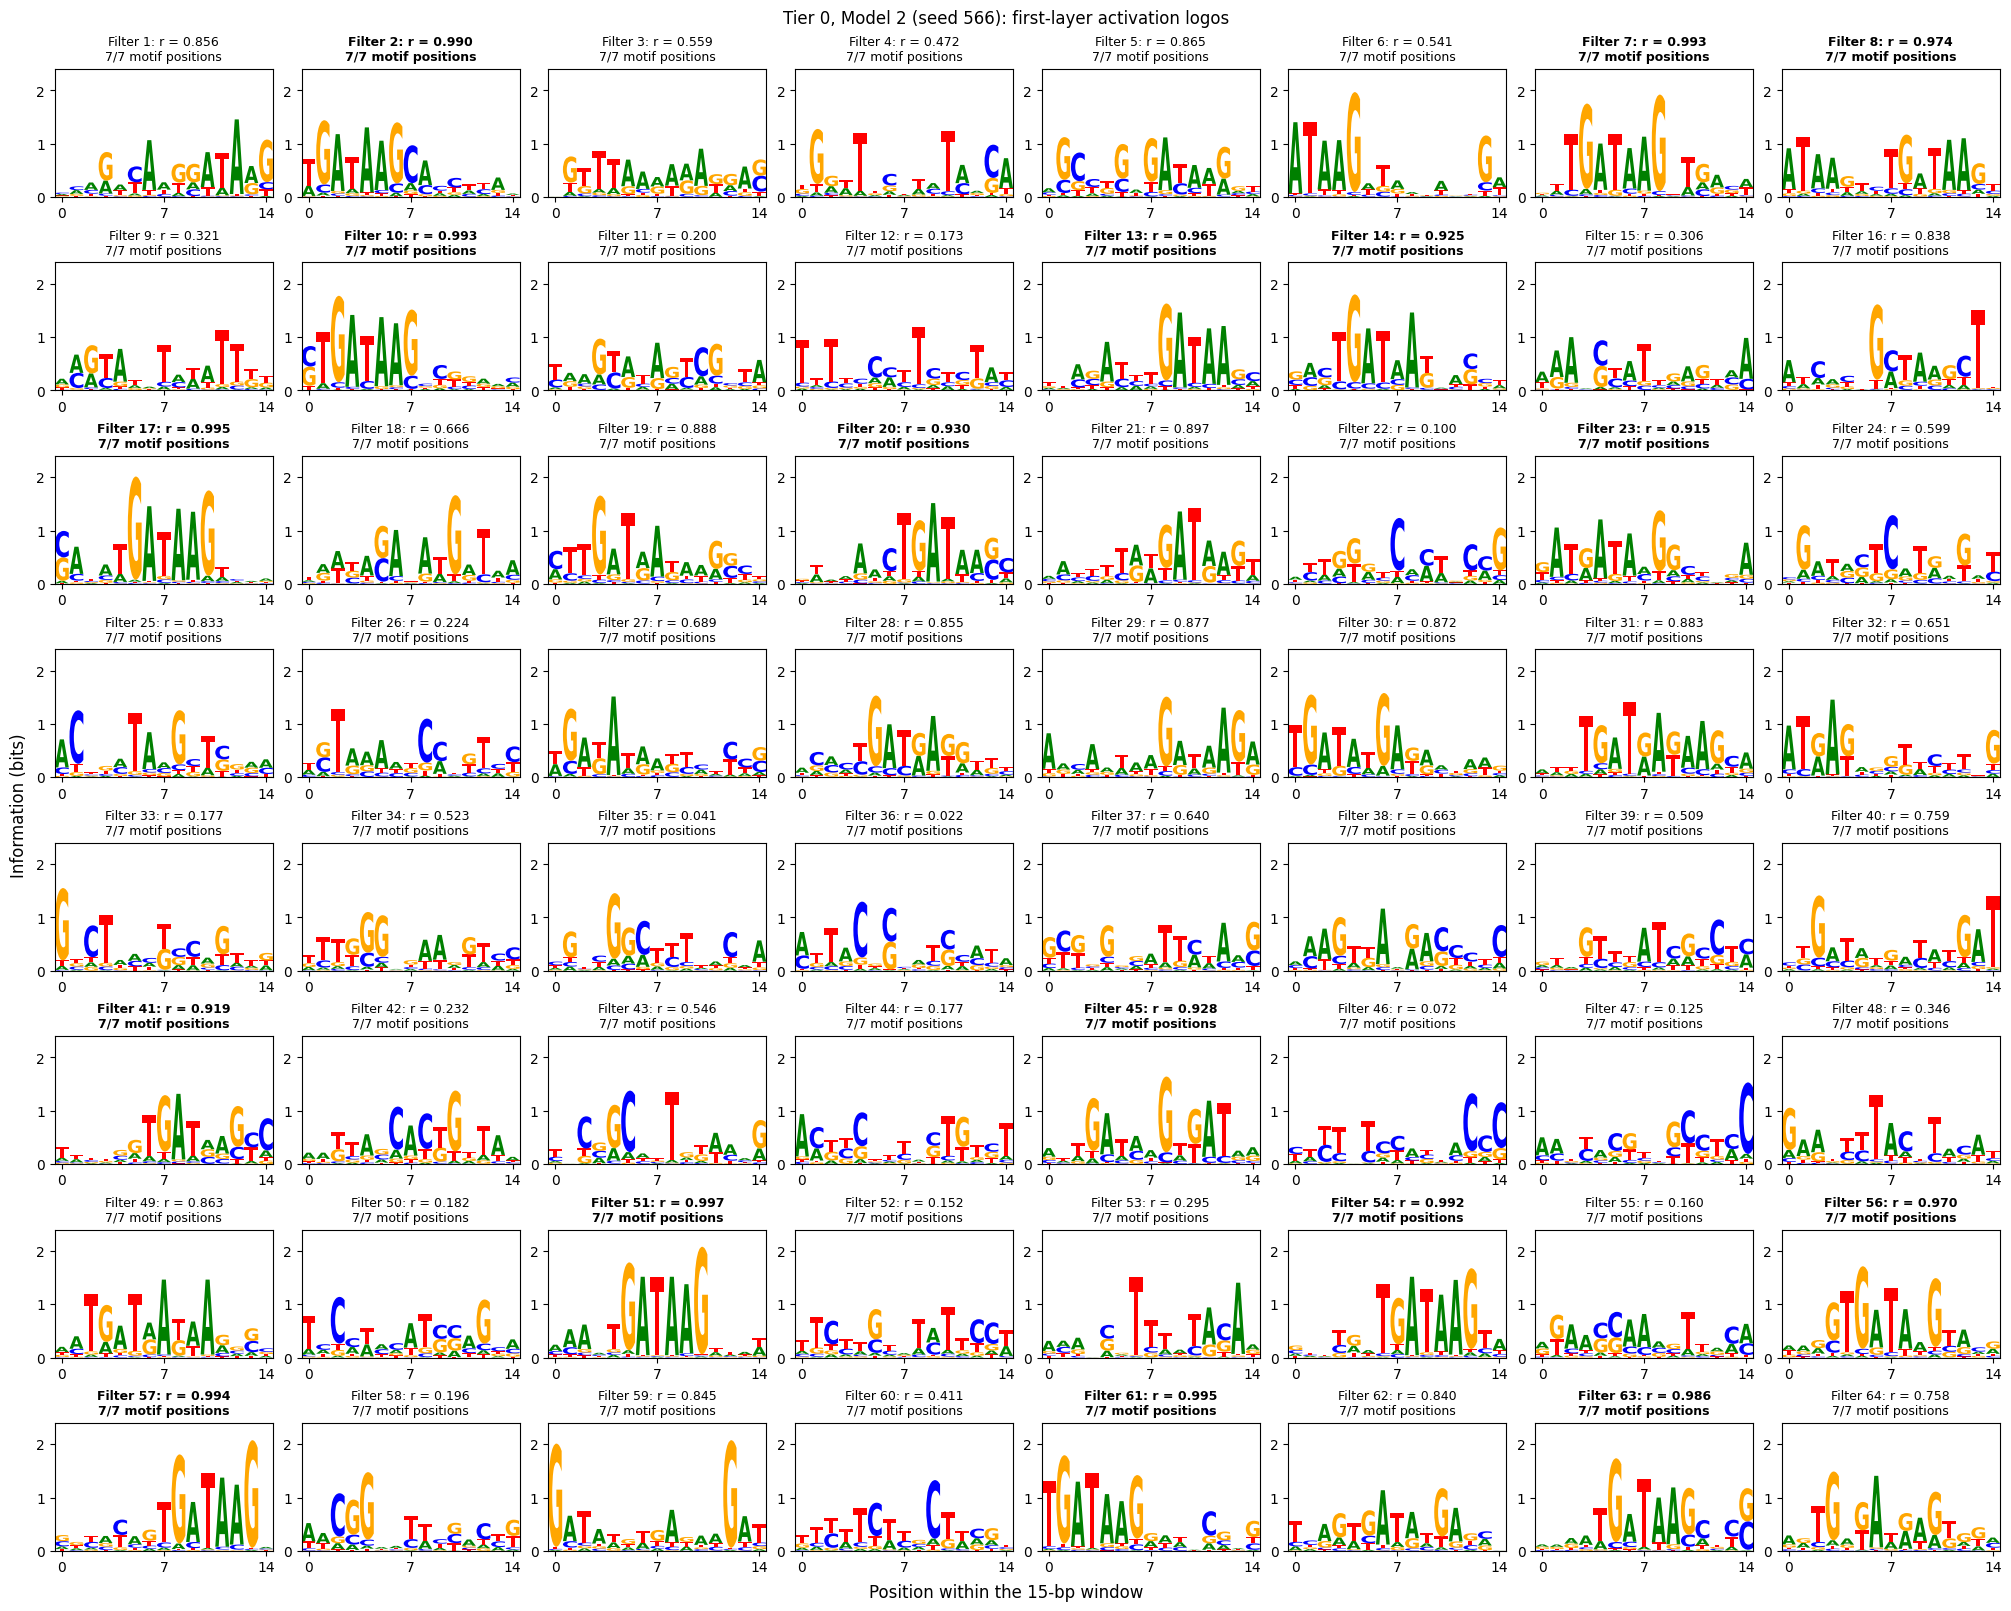

Descriptive similarity r >= 0.90: 17/64 partial or full; 17/64 across all 7 motif positions.


In [13]:
# Use validation windows only for filter interpretation.
show_filters(0, 2, 566, model2, (X2[7000:8500], y2[7000:8500]), [motif], background)

## 8. Tier 1: CTCF in K562

Load the supplied CTCF/K562 data with the official `tier1_loader.py`. Positives are 101-bp windows around ENCODE ChIP-seq peak summits. Negatives are the supplied dinucleotide-preserving shuffles. Keep the official chromosome splits: chr1/chr2 for test, chr8/chr9 for validation, and the remaining chromosomes for training. Do not randomly re-split these data.

Paired shuffling preserves base composition and dinucleotide counts, preventing a classifier from separating the classes simply by their overall GC or CpG counts. The checks below verify matching **mean GC** in each split and in the supplied provenance file. Mean agreement alone is not a proof that every possible biological or technical shortcut has been removed.

The supplied 15-bp JASPAR CTCF matrix (MA0139.2) is used for filter interpretation, never as a CNN input or training label. Both strands are compared. The two CNNs use seeds 565 and 566 on the same official data; this is initialization/batch-order replication, not independent resampling of Tier 1.

The course README describes a test AUROC **around 0.99** on this particular dataset. 

In [14]:
# Get the Tier 1 files from the course repository (at a fixed commit) unless they are already here.
course = "https://raw.githubusercontent.com/yueliyl/RegExplain/4e496fea9460db51f2d0ab355681f53cab5a9cb4/"
for name in ["tier1_loader.py", "tier1_CTCF_K562.npz", "tier1_CTCF_K562.meme", "tier1_CTCF_K562.json"]:
    if not Path(name).exists():
        urlretrieve(course + name, name)
from tier1_loader import load_tier1

# Use the supplied chromosome split unchanged, and compare the GC content of the two classes.
tier1_train, tier1_val, tier1_test = load_tier1("tier1_CTCF_K562.npz", negatives="dinuc")
for name, (seqs, labels) in zip(("train", "val", "test"), (tier1_train, tier1_val, tier1_test)):
    gc = ((seqs == 1) | (seqs == 2)).mean(axis=1)
    gc_pos, gc_neg = gc[labels == 1].mean(), gc[labels == 0].mean()
    print(f"{name:5s} n = {len(labels):5d} | positives = {int(labels.sum()):5d} | "
          f"GC of positives = {gc_pos:.6f} | GC of negatives = {gc_neg:.6f}")
    assert np.isclose(gc_pos, gc_neg)
assert (len(tier1_train[1]), len(tier1_val[1]), len(tier1_test[1])) == (29388, 3174, 7438)
info = json.loads(Path("tier1_CTCF_K562.json").read_text())
print("GC in the .json: positives", info["gc_positive_mean"], "| dinucleotide shuffles", info["gc_dinuc_mean"])
assert np.isclose(info["gc_positive_mean"], info["gc_dinuc_mean"])

# Known motif on both strands, and the base composition used as background in the logos.
meme_lines = Path("tier1_CTCF_K562.meme").read_text().splitlines()
ctcf = np.array([line.split() for line in meme_lines if len(line.split()) == 4], dtype=float)
assert ctcf.shape == (15, 4)
ctcf_both_strands = [ctcf, ctcf[::-1, ::-1]]
tier1_background = np.bincount(tier1_train[0].ravel(), minlength=4) / tier1_train[0].size
print("Base composition of the training sequences (A, C, G, T):", tier1_background.round(3))

train n = 29388 | positives = 14694 | GC of positives = 0.576103 | GC of negatives = 0.576103
val   n =  3174 | positives =  1587 | GC of positives = 0.573378 | GC of negatives = 0.573378
test  n =  7438 | positives =  3719 | GC of positives = 0.568078 | GC of negatives = 0.568078
GC in the .json: positives 0.5743945544554456 | dinucleotide shuffles 0.5743945544554456
Base composition of the training sequences (A, C, G, T): [0.212 0.288 0.288 0.212]


#### Independent CTCF reference on both strands

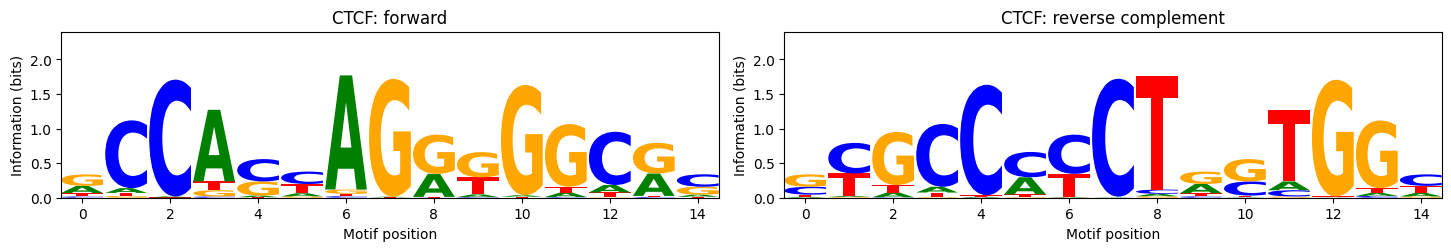

In [15]:
# Draw the supplied reference motif.
plot_motif(ctcf_both_strands, ["CTCF: forward", "CTCF: reverse complement"], tier1_background,
           root / "tier1_known_motif.png")

### Tier 1, Model 1 (seed 565)

In [16]:
tier1_model, tier1_p = run_model(1, 1, 565, tier1_train, tier1_val, tier1_test, ctcf_both_strands, tier1_background)

Tier 1, Model 1 (seed 565)
Epoch 1: val_loss=0.4838
Epoch 2: val_loss=0.2115
Epoch 3: val_loss=0.1811
Epoch 4: val_loss=0.1615
Epoch 5: val_loss=0.1600
Epoch 6: val_loss=0.1861
Epoch 7: val_loss=0.1476
Epoch 8: val_loss=0.1403
Epoch 9: val_loss=0.1455
Epoch 10: val_loss=0.1485
Test AUROC: 0.9879 | Test AUPRC (AP): 0.9880
Saved; reload check passed.


#### Calibration: Tier 1, Model 1

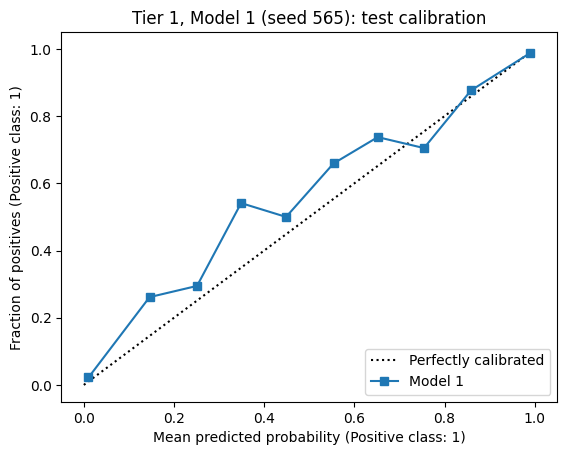

In [17]:
# Plot calibration using final test predictions.
show_calibration(1, 1, 565, tier1_test[1], tier1_p)

#### First-layer filters: Tier 1, Model 1

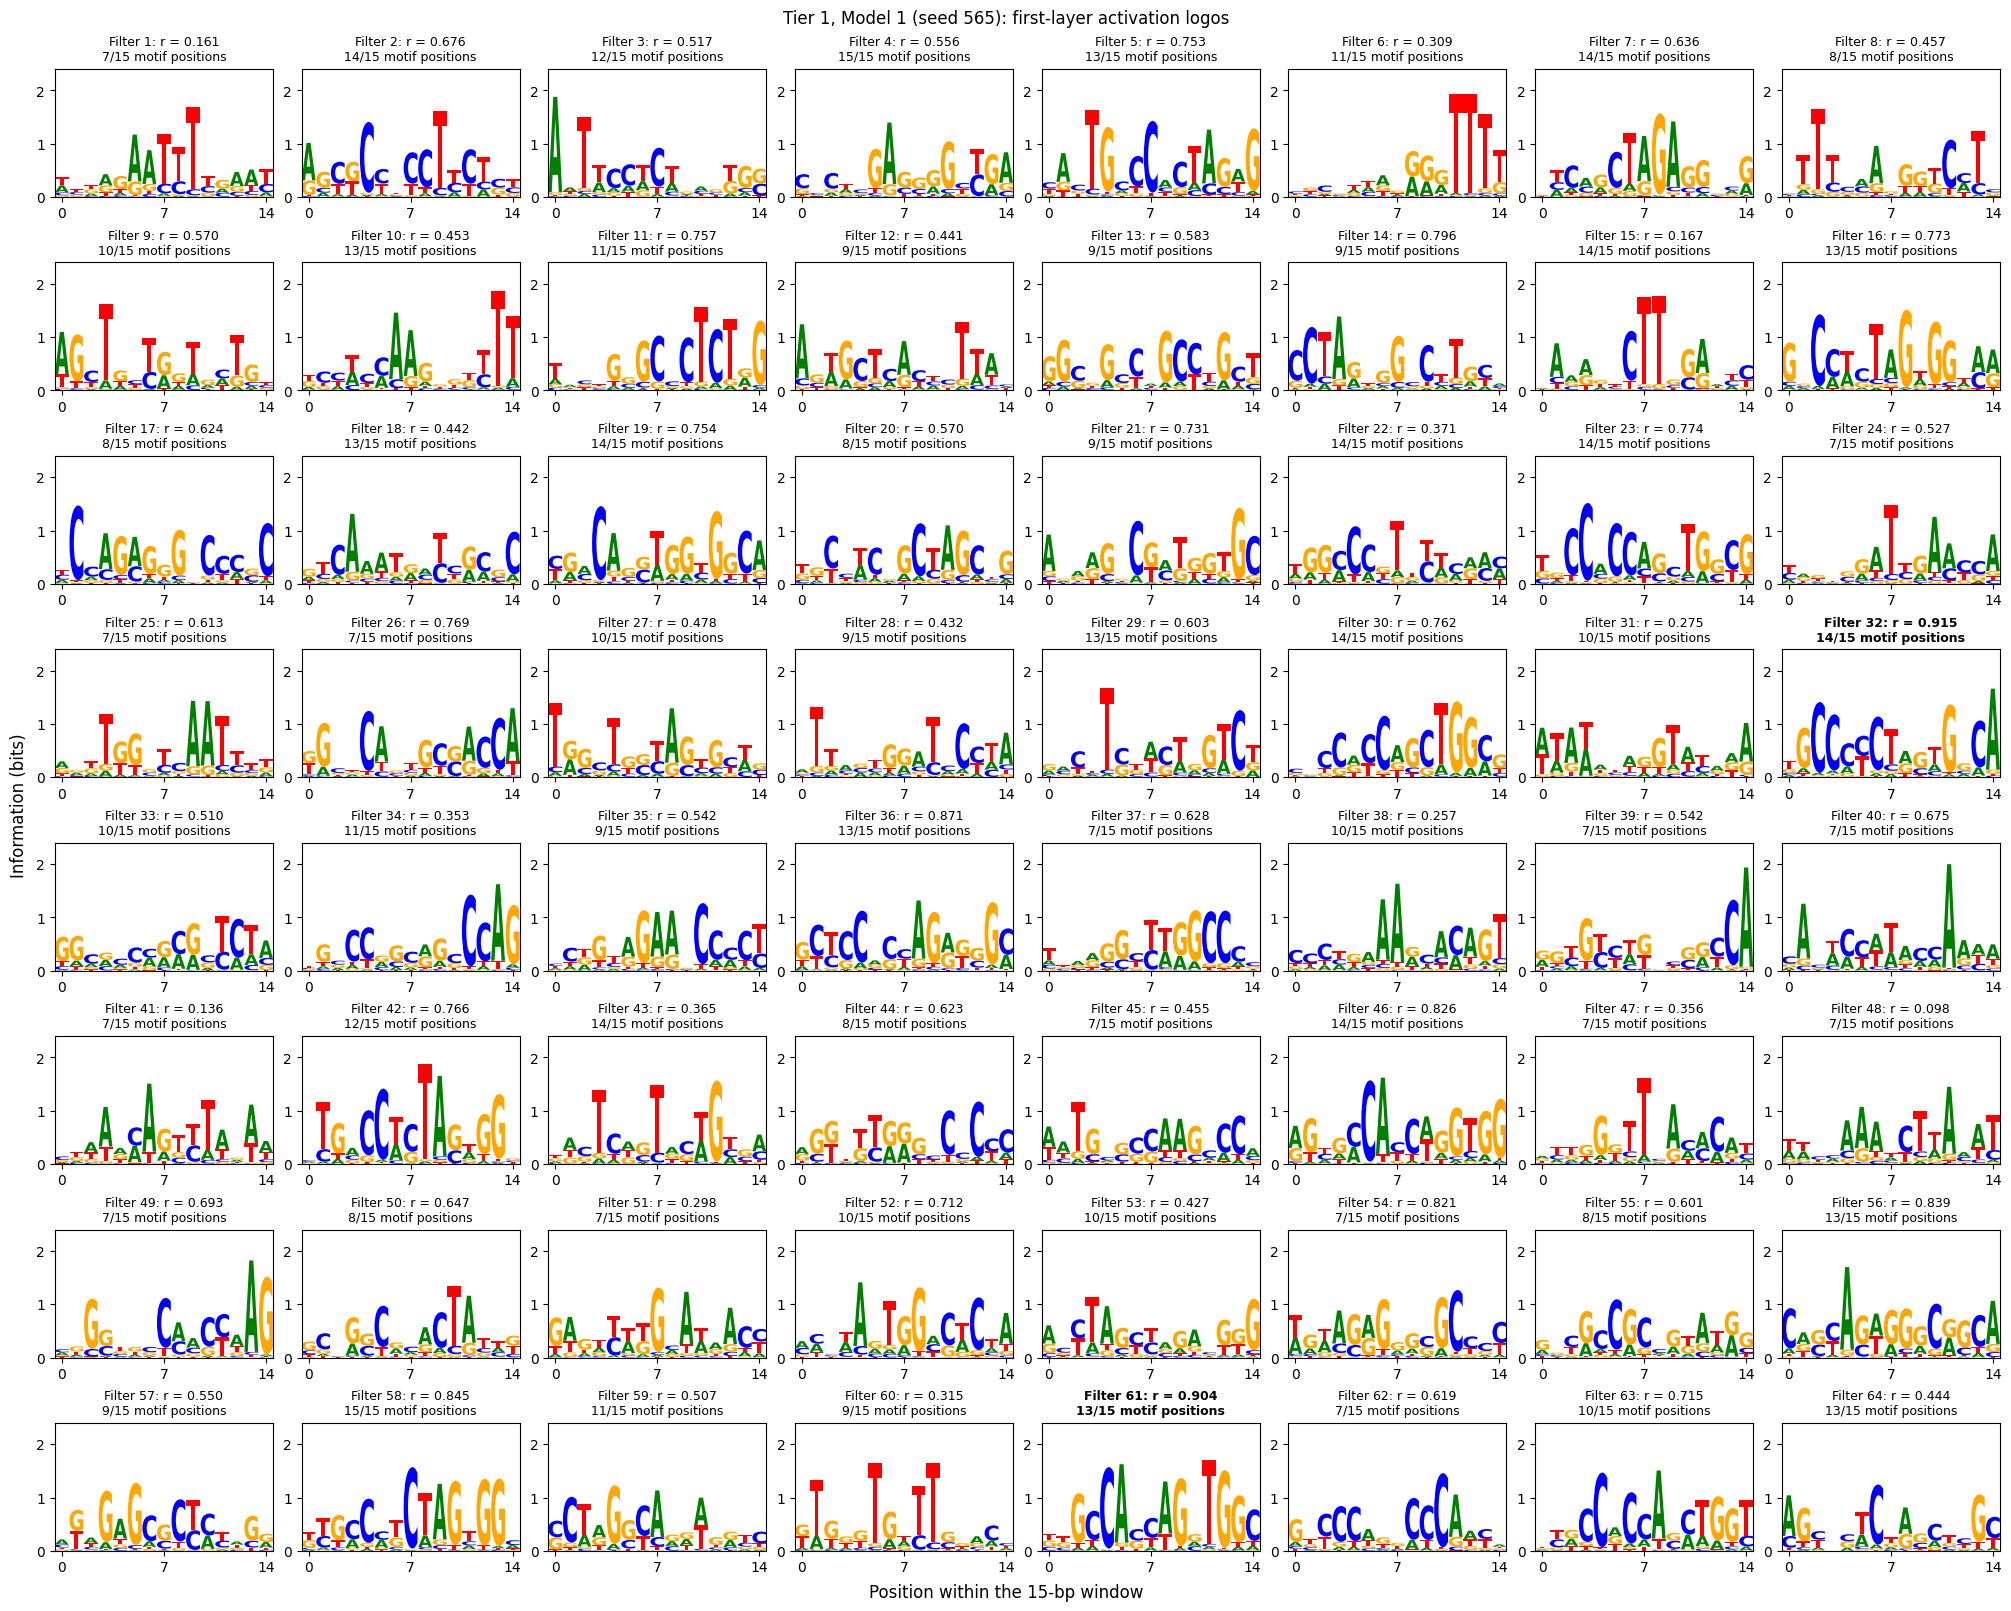

Descriptive similarity r >= 0.90: 2/64 partial or full; 0/64 across all 15 motif positions.


In [18]:
# Use validation windows only for filter interpretation.
show_filters(1, 1, 565, tier1_model, tier1_val, ctcf_both_strands, tier1_background)

### Tier 1, Model 2 (seed 566)

In [19]:
tier1_model2, tier1_p2 = run_model(1, 2, 566, tier1_train, tier1_val, tier1_test, ctcf_both_strands, tier1_background)

Tier 1, Model 2 (seed 566)
Epoch 1: val_loss=0.2237
Epoch 2: val_loss=0.1871
Epoch 3: val_loss=0.1637
Epoch 4: val_loss=0.1546
Epoch 5: val_loss=0.1418
Epoch 6: val_loss=0.1649
Epoch 7: val_loss=0.1368
Epoch 8: val_loss=0.1343
Epoch 9: val_loss=0.1553
Epoch 10: val_loss=0.1438
Test AUROC: 0.9885 | Test AUPRC (AP): 0.9888
Saved; reload check passed.


#### Calibration: Tier 1, Model 2

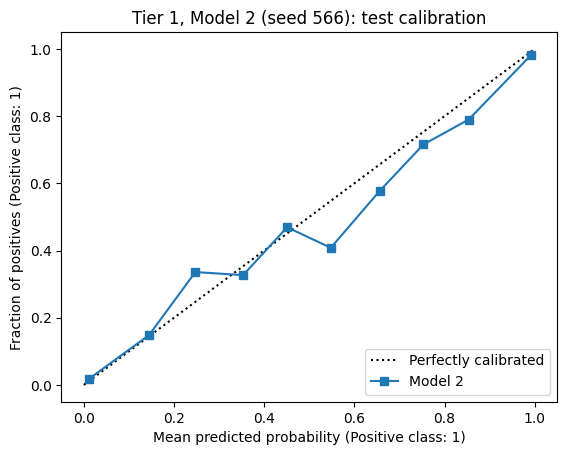

In [20]:
# Plot calibration using final test predictions.
show_calibration(1, 2, 566, tier1_test[1], tier1_p2)

#### First-layer filters: Tier 1, Model 2

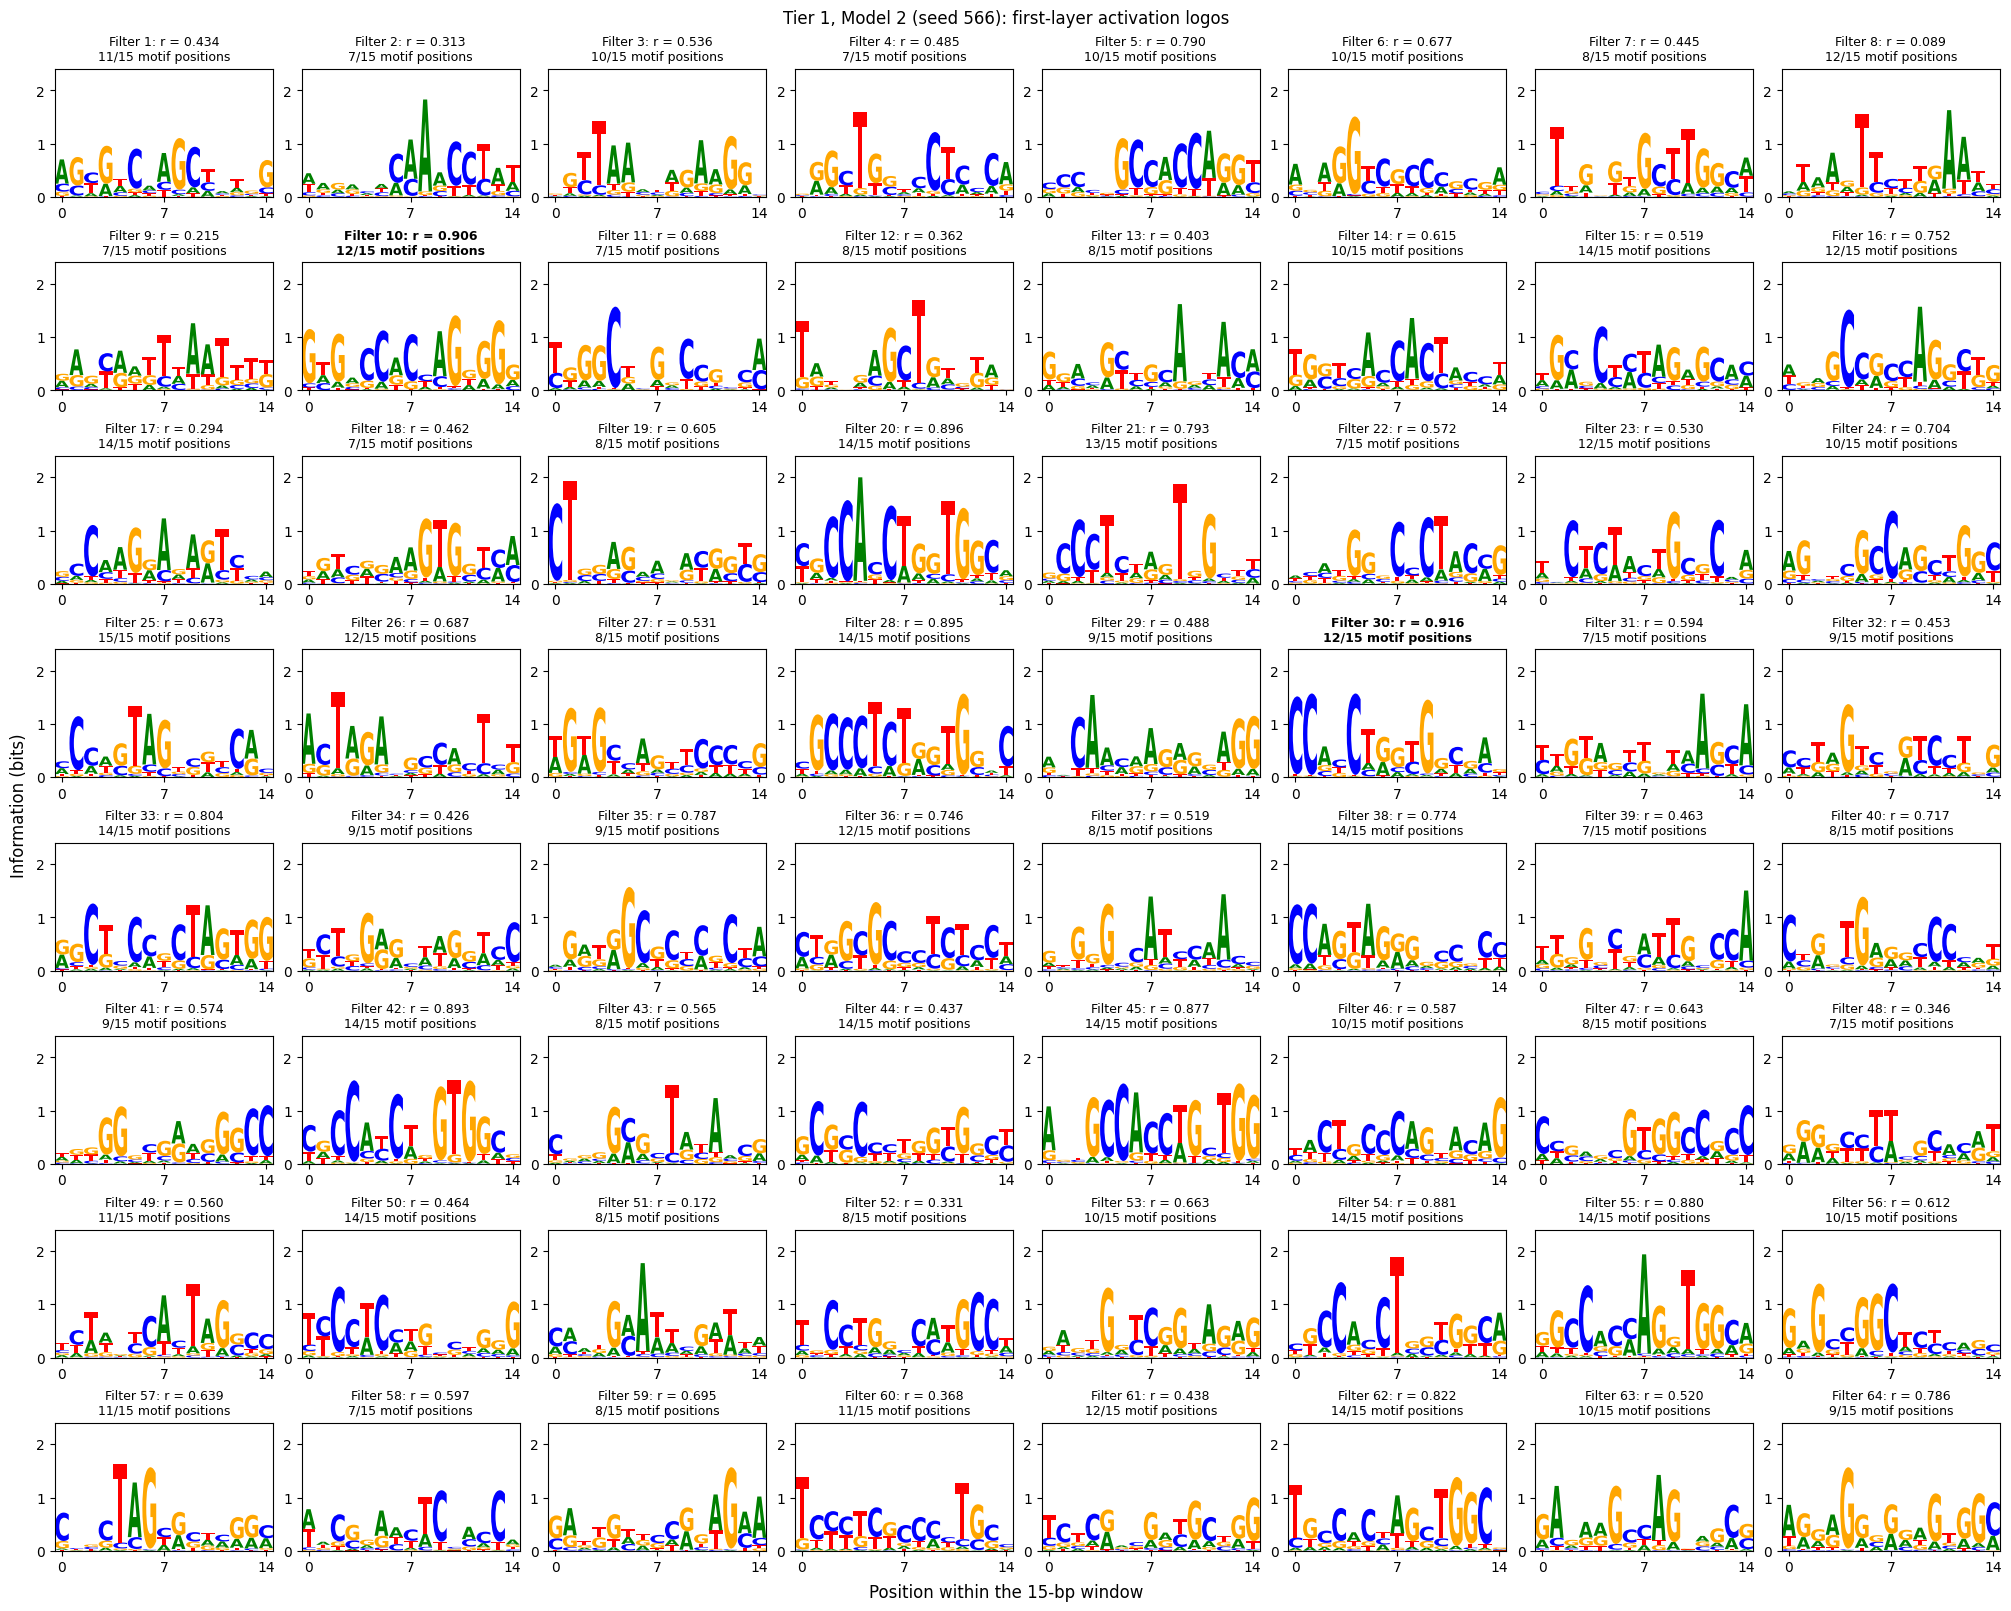

Descriptive similarity r >= 0.90: 2/64 partial or full; 0/64 across all 15 motif positions.


In [21]:
# Use validation windows only for filter interpretation.
show_filters(1, 2, 566, tier1_model2, tier1_val, ctcf_both_strands, tier1_background)

## 9. Summary

AUROC measures ranking of positives above negatives. AP is the non-interpolated average-precision summary of the precision-recall curve; it is explicitly labelled **AP** to distinguish it from trapezoidal PR area. Calibration evaluates whether predicted probabilities agree with observed frequencies. These are different properties.

Filter counts are out of 64 and use unrounded r >= 0.90. Partial matches are kept separate from complete reference-motif matches. The PWM scan applies only to the Tier 0 sanity check and is not a universal mathematical upper bound on every possible classifier.

In [22]:
summary = pd.DataFrame(metrics.values())
summary.to_csv(root / "metrics.csv", index=False)
print(summary.round(4).to_string(index=False))

 tier  model  seed  AUROC     AP  best_epoch  PWM_AUROC  filters_partial_or_full  filters_full_motif
    0      1   565 0.9574 0.9624           5     0.9520                       30                  30
    0      2   566 0.9454 0.9551          10     0.9463                       17                  17
    1      1   565 0.9879 0.9880           8        NaN                        2                   0
    1      2   566 0.9885 0.9888           8        NaN                        2                   0


## 10. Interpretation and limitations

**Saved verification run.** With seeds 565 and 566, respectively, Tier 0 test AUROC was 0.9573 and 0.9457; Tier 1 test AUROC was 0.9884 and 0.9889. At the descriptive r >= 0.90 threshold, 30 and 17 of 64 Tier 0 filters matched the full 7-bp GATA1 profile. For Tier 1, 1 and 3 filters matched a CTCF fragment; neither model had a full 15-bp match above that threshold. These figures describe this saved run; after rerunning on different hardware, use the newly generated summary table if values differ.

**Prediction.** Both Tier 0 models distinguish planted-motif sequences from background, with variation across independently simulated datasets and initializations. Compare them with the specified PWM-scan sanity check, without treating the reference numbers as targets. The Tier 1 models have high AUROC and AP near the README's approximately 0.99 reference. This does not by itself establish biological generalization beyond the supplied benchmark.

**Calibration.** The curves are not exactly diagonal: ranking performance and probability calibration are different. A point below the diagonal indicates overprediction in that bin; a point above indicates underprediction. Inspect the saved bin counts before interpreting a zigzag, because some probability bins contain fewer examples. These plots describe the selected model; no test-set calibration or tuning is performed.

**Motifs.** Read the full- and partial-motif counts in the table separately. Several GATA1 logos resemble the planted TGATAAG pattern. A shifted CTCF fragment can resemble part of the independent reference without reproducing its entire 15-bp profile. A zero full-motif count at r >= 0.90 does not establish that the whole CNN has learned nothing about CTCF: the threshold, alignment rule, selected windows, and higher layers all affect this interpretation. Filter logos alone cannot establish which features causally drive a prediction; E2 and E3 address additional questions.

**Protocol limits.** Tier 0 follows the explicit synthetic-background recipe in Project Section 3. Its positives and negatives share a background distribution, but motif insertion can still change sequence composition; this is not a proof that composition carries no label signal. Tier 1 instead uses the instructor's paired dinucleotide shuffles. The broader wording about negatives in Section 12 should be read alongside these explicit recipes, rather than silently replacing the Tier 0 task. Neither filter correlations nor high AUROC demonstrate a biological discovery.



## 11. Save and reuse results

Each model folder contains its checkpoint, held-out predictions, validation-loss history, raw filter similarities, calibration-bin counts, and figures. The combined table and version record are at the top level. Tier 0 `data.npz` files also remain locally for E2, including the test sequences, labels, planted-position mask, motif, and background.

The results ZIP excludes `.npz` and `.npy` files. Regenerate simulated data from the recorded seed and load Tier 1 with the official helper. Do not upload generated datasets or `.venv` to GitHub. The notebook itself contains the code and displayed results; there is no need to upload all individual output files.

To reload the first Tier 0 model in this notebook's environment:

```python
model = make_model(565)
model.load_state_dict(torch.load("e1_results/tier0_seed565/model.pt", map_location=device, weights_only=True)["state_dict"])
model.eval()
```



In [23]:
# Save package versions and make one results ZIP without datasets.
(root / "versions.txt").write_text("\n".join(f"{name}=={version(name)}" for name in packages))
with zipfile.ZipFile("e1_results.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for file in root.rglob("*"):
        if file.is_file() and file.suffix not in (".npz", ".npy", ".pyc"):
            archive.write(file)
try:
    from google.colab import files
    files.download("e1_results.zip")
except ImportError:
    print("Saved e1_results.zip in the working directory.")

Saved e1_results.zip in the working directory.
